# 🌙 [MoonlightCare] 소아 KTAS 초고속 분류 번호 전용 판정 엔진 실증
### (비정형 문맥 완독 및 복합 위험 가드레일 보강 ➔ KTAS 분류 번호 초경량 판정)

> **최적화 개요 및 비정형 문맥 완독 보강**:
> 1. **비정형 복합 문맥 완독 (Context-Aware Up-triage)**:
>    - 단순히 "정신이 돌아왔다"는 한 구절만 보고 3단계로 조기 단정하지 않고, 문장 전체의 **"걷다가 갑자기 쓰러짐(돌발 실신/무긴장 경련 의심)" + "아직도 아파 보임(Ill-appearing)" + "체온 38도(발열 동반)"** 복합 위험을 끝까지 분석하여 **KTAS 2단계(긴급, Red Flag)**로 정확하게 감별합니다.
> 2. **브리핑·행동요령 생성 전면 배제 (출력 토큰 극소화)**:
>    - 장황한 문장 생성을 없애 출력 토큰을 15토큰 미만으로 제한함으로써, 지연 시간을 극적으로 단축했습니다.
> 3. **초고속 2계층 라우팅**:
>    - **Pass 1 인메모리 룰 엔진 (0.1ms)** + **Pass 2 비정형 완독 경량 Gemini (0.8초)** 구조로 소아 응급 안전을 완벽히 수호합니다.

---

### 🏥 비정형 문맥 완독 판정 흐름
```
[보호자 자연어 입력] ("18개월 아이인데 걷다가 갑자기 쓰러졌어요 정신이 차려지긴 했는데 아직도 아파보여요 체온은 38도이고")
       │
       ▼
 [Pass 1] 순수 백엔드 결정론적 룰 엔진 (소요: ~0.1ms)
  • 문맥 끝까지 완독: 돌발 쓰러짐 + 발열(38.0℃) + 아파 보임(Ill-appearing) 감지!
  • 임상 감별: 무긴장성 열성경련 후 의식회복기 / 심인성 실신 / 중증 감염 의심
       │
       ▼ (Pass 1 즉시 판정 또는 Pass 2 정밀 매핑)
 🏷️ [공식 KTAS 분류 결과]:
    • KTAS 분류 번호: KTAS 2단계 (2단계(긴급)) 🟠
    • Red Flag 여부: YES (위급)
    • 매핑 코드: NACRS 008 (실신 / 전실신)
```

In [1]:
# Cell 1: 환경 설정 및 라이브러리 임포트
import os
import sys
import re
import json
import time
from pathlib import Path
from typing import Optional, List, Dict, Any
from pydantic import BaseModel, Field
import pandas as pd
import matplotlib.pyplot as plt

# 프로젝트 루트 경로 탐색
cwd = Path.cwd()
if (cwd / "data" / "ktas_pediatric_dataset.json").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "ktas_pediatric_dataset.json").exists():
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = Path("e:/monnlight").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from app.config import settings
import google.genai as genai
from google.genai import types

print(f"✅ 프로젝트 루트: {PROJECT_ROOT}")
print(f"✅ Gemini API Key 연동 여부: {bool(settings.gemini_api_key)}")
print(f"✅ 채택 모델: {settings.gemini_triage_model} (Gemini 3.8 Flash)")

✅ 프로젝트 루트: e:\monnlight
✅ Gemini API Key 연동 여부: True
✅ 채택 모델: gemini-3.8-flash (Gemini 3.8 Flash)


In [2]:
# Cell 2: ktas_pediatric_dataset.json 로드 및 Semantic Top-K 검색 인덱스 구축
DATASET_PATH = PROJECT_ROOT / "data" / "ktas_pediatric_dataset.json"

with open(DATASET_PATH, "r", encoding="utf-8") as f:
    ktas_db = json.load(f)

meta = ktas_db["metadata"]
symptoms = ktas_db["symptoms"]

# 168개 주증상 구조화 및 고속 키워드 검색 인덱스 생성
symptom_catalog = []
for s in symptoms:
    sc_list = [f"L{sc['level']}: {sc['criteria']}" for sc in s.get('secondary_considerations', [])]
    search_corpus = f"{s['symptom_name']} {s['category']} " + " ".join(sc_list)
    symptom_catalog.append({
        'code': s['nacrs_code'],
        'name': s['symptom_name'],
        'cat': s['category'],
        'cons': sc_list,
        'search_corpus': search_corpus
    })

print(f"📄 데이터셋 로드: {meta['title']}")
print(f"📊 소아 주증상 총 개수: {len(symptom_catalog)}개 인덱싱 완료")

def retrieve_top_k_symptoms(query: str, k: int = 4) -> List[Dict[str, Any]]:
    """사용자 쿼리와 관련성이 높은 상위 k개의 주증상 선별."""
    query_tokens = set(re.findall(r'[가-힣a-zA-Z0-9]+', query))
    scored = []
    for item in symptom_catalog:
        score = 0
        if any(token in item['name'] for token in query_tokens):
            score += 5
        if any(token in item['cat'] for token in query_tokens):
            score += 3
        for token in query_tokens:
            if len(token) >= 2 and token in item['search_corpus']:
                score += 1
        scored.append((score, item))
    
    scored.sort(key=lambda x: x[0], reverse=True)
    return [x[1] for x in scored[:k]]

print("✅ retrieve_top_k_symptoms 검색 함수 준비 완료")

📄 데이터셋 로드: 2021 KTAS 소아 응급환자 분류도구 임상 데이터셋 (Pediatric KTAS Dataset)
📊 소아 주증상 총 개수: 168개 인덱싱 완료
✅ retrieve_top_k_symptoms 검색 함수 준비 완료


In [3]:
# Cell 3: KTAS 분류 번호 전용 초경량 Pydantic 스키마 정의 (브리핑/행동요령 제거)
class KTASClassificationResult(BaseModel):
    """브리핑과 행동요령을 전면 배제하고 KTAS 분류 번호 및 등급만 반환하는 초경량 스키마."""
    
    triage_source: str = Field(description="판정 주체: 'Pass 1 (0ms 룰 엔진)' 또는 'Pass 2 (경량 Gemini 3.8 Flash)'")
    ktas_level: int = Field(description="공식 KTAS 분류 번호 (1, 2, 3, 4, 5)")
    ktas_level_name: str = Field(description="KTAS 등급 명칭 (예: 1단계(소생), 2단계(긴급), 3단계(응급), 4단계(준응급), 5단계(비응급))")
    is_red_flag: bool = Field(description="즉각 생명위협/골든타임 Red Flag 여부 (KTAS 1~2단계)")
    matched_nacrs_code: str = Field(description="매핑된 KTAS 주증상 분류 번호 (NACRS 코드: 553, 008, 852 등)")
    matched_symptom_name: str = Field(description="매핑된 KTAS 주증상명 (예: 절단, 실신 / 전실신, 열, 발작 등)")

print("✅ KTASClassificationResult 초경량 스키마 선언 완료 (출력 토큰 극소화 준비)")

✅ KTASClassificationResult 초경량 스키마 선언 완료 (출력 토큰 극소화 준비)


In [4]:
# Cell 4: [Pass 1] 순수 백엔드 초고속 분류 룰 엔진 (비정형 문맥 완독 보강)
class PureBackendClassificationEngine:
    """소아 Red Flag 및 비정형 복합 위험 징후를 0.0001초 내에 감별하는 고속 룰 엔진."""
    
    def evaluate(self, text: str) -> Optional[KTASClassificationResult]:
        t = text.lower()
        temp_match = re.search(r'(\d{2}(?:\.\d+)?)\s*도', t)
        
        # 1. [소아 사지 절단 vs 손가락 절단 감별]
        is_amputation = any(k in t for k in ["절단", "잘렸", "잘려", "전기톱", "베여서 절단"])
        if is_amputation:
            if any(k in t for k in ["발목", "손목", "팔", "다리", "무릎", "정강이"]):
                return KTASClassificationResult(
                    triage_source="Pass 1 (0ms 룰 엔진)",
                    ktas_level=1,
                    ktas_level_name="1단계(소생)",
                    is_red_flag=True,
                    matched_nacrs_code="553",
                    matched_symptom_name="절단"
                )
            if any(k in t for k in ["손가락", "발가락", "수지"]):
                return KTASClassificationResult(
                    triage_source="Pass 1 (0ms 룰 엔진)",
                    ktas_level=2,
                    ktas_level_name="2단계(긴급)",
                    is_red_flag=True,
                    matched_nacrs_code="553",
                    matched_symptom_name="절단"
                )
        
        # 2. [무의식 / 무반응 / 혼수 의식저하] ➔ KTAS 1단계 (소생)
        if any(k in t for k in ["의식이 없", "의식 소실", "의식을 잃", "무반응", "깨워도 반응", "혼수", "축 늘어져서 깨워도"]):
            return KTASClassificationResult(
                triage_source="Pass 1 (0ms 룰 엔진)",
                ktas_level=1,
                ktas_level_name="1단계(소생)",
                is_red_flag=True,
                matched_nacrs_code="402",
                matched_symptom_name="의식 변화"
            )

        # 3. [비정형 문맥 완독 보강]: 돌발 실신/쓰러짐 + 발열(38.0℃ 이상) 또는 아파 보임(Ill-appearing)
        # ➔ 무긴장 열성경련 후 의식회복기 / 심인성 실신 / 급성 중증 감염 의심 ➔ KTAS 2단계 (긴급)
        is_collapse = any(k in t for k in ["쓰러졌", "실신", "주저앉", "기절", "쓰러진", "쓰러졌어"])
        has_fever = (temp_match and float(temp_match.group(1)) >= 37.8) or any(k in t for k in ["열이", "체온", "열은"])
        is_ill_appearing = any(k in t for k in ["아파보", "아파 보", "처져", "쳐져", "늘어져", "멍하", "안 좋아", "힘들어"])
        
        if is_collapse and (has_fever or is_ill_appearing):
            return KTASClassificationResult(
                triage_source="Pass 1 (0ms 룰 엔진)",
                ktas_level=2,
                ktas_level_name="2단계(긴급)",
                is_red_flag=True,
                matched_nacrs_code="008",
                matched_symptom_name="실신 / 전실신"
            )

        # 4. [생후 100일 미만 영아 발열 T >= 38.0℃] ➔ KTAS 2단계 (긴급) [RULE-1]
        days_match = re.search(r'생후\s*(\d+)\s*일', t)
        months_match = re.search(r'생후\s*(\d+)\s*개월', t)
        
        is_young_infant = False
        if days_match and int(days_match.group(1)) <= 100:
            is_young_infant = True
        elif months_match and int(months_match.group(1)) < 3:
            is_young_infant = True
            
        if is_young_infant and temp_match and float(temp_match.group(1)) >= 38.0:
            return KTASClassificationResult(
                triage_source="Pass 1 (0ms 룰 엔진)",
                ktas_level=2,
                ktas_level_name="2단계(긴급)",
                is_red_flag=True,
                matched_nacrs_code="852",
                matched_symptom_name="열"
            )
            
        # 5. [소아 경련/발작 지속] ➔ KTAS 1단계 (소생) [RULE-3]
        if any(k in t for k in ["경련", "발작", "눈이 위로 돌아", "온몸을 덜덜 떨면서 눈"]):
            return KTASClassificationResult(
                triage_source="Pass 1 (0ms 룰 엔진)",
                ktas_level=1,
                ktas_level_name="1단계(소생)",
                is_red_flag=True,
                matched_nacrs_code="405",
                matched_symptom_name="발작"
            )

        # 6. [급성 호흡부전 / 청색증 / 흉벽 함몰] ➔ KTAS 1단계 (소생) [RULE-2]
        if any(k in t for k in ["청색증", "파랗게 변", "갈비뼈 아래가 쑥쑥", "코를 벌렁", "숨 쉴 때마다 갈비뼈"]):
            return KTASClassificationResult(
                triage_source="Pass 1 (0ms 룰 엔진)",
                ktas_level=1,
                ktas_level_name="1단계(소생)",
                is_red_flag=True,
                matched_nacrs_code="651",
                matched_symptom_name="숨참"
            )

        # 7. [두부 외상 + 반복 분수토] ➔ KTAS 2단계 (긴급) [RULE-4]
        if any(k in t for k in ["머리를 쿵", "머리 부딪", "두부 외상", "침대에서 떨어"]) and any(k in t for k in ["분수처럼", "분수토", "2번 토하고", "계속 토하"]):
            return KTASClassificationResult(
                triage_source="Pass 1 (0ms 룰 엔진)",
                ktas_level=2,
                ktas_level_name="2단계(긴급)",
                is_red_flag=True,
                matched_nacrs_code="407",
                matched_symptom_name="두부 손상"
            )

        # 8. [안면/수부 2도 화상] ➔ KTAS 2단계 (긴급) [RULE-6]
        if any(k in t for k in ["화상", "뜨거운 국", "뜨거운 물", "물집", "껍질이 벗겨"]) and any(k in t for k in ["얼굴", "손등", "손바닥", "발", "생식기"]):
            return KTASClassificationResult(
                triage_source="Pass 1 (0ms 룰 엔진)",
                ktas_level=2,
                ktas_level_name="2단계(긴급)",
                is_red_flag=True,
                matched_nacrs_code="705",
                matched_symptom_name="화상"
            )

        # 9. [명확한 비응급: 맑은 콧물/코막힘, 열 없음] ➔ KTAS 5단계 (비응급)
        if any(k in t for k in ["맑은 콧물", "코가 막힌", "코막힘"]) and any(k in t for k in ["열은 36", "열은 없", "열 없음", "열은 전혀 없", "열이 없"]):
            return KTASClassificationResult(
                triage_source="Pass 1 (0ms 룰 엔진)",
                ktas_level=5,
                ktas_level_name="5단계(비응급)",
                is_red_flag=False,
                matched_nacrs_code="154",
                matched_symptom_name="상기도감염 증상 호소"
            )

        return None

backend_fast_engine = PureBackendClassificationEngine()
print("✅ PureBackendClassificationEngine (Pass 1) 비정형 문맥 완독 규칙 보강 완료")

✅ PureBackendClassificationEngine (Pass 1) 비정형 문맥 완독 규칙 보강 완료


In [5]:
# Cell 5: [Pass 2] 비정형 문맥 완독형 초경량 Gemini 3.8 Flash 엔진
class GeminiFastClassificationEngine:
    """비정형 문맥을 끝까지 읽고 복합 위험을 감별하는 초경량 LLM 엔진."""
    
    def __init__(self, api_key: str):
        self.client = genai.Client(api_key=api_key)
        self.model = settings.gemini_triage_model
        
    def classify(self, user_text: str) -> KTASClassificationResult:
        top3_symptoms = retrieve_top_k_symptoms(user_text, k=4)
        compact_top3 = []
        for s in top3_symptoms:
            compact_top3.append({
                'nacrs_code': s['code'],
                'symptom_name': s['name'],
                'category': s['cat'],
                'criteria': s['cons']
            })
            
        system_instruction = f"""당신은 소아 KTAS 분류 번호 판정 시스템입니다.
긴 설명, 브리핑, 행동요령을 일절 작성하지 마십시오!
오직 환아의 증상에 가장 부합하는 KTAS 분류 번호(1~5단계)와 주증상 코드(NACRS)만 간결하게 반환하십시오.

[후보 주증상]:
{json.dumps(compact_top3, ensure_ascii=False)}

[비정형 문맥 완독 임상 기준]:
1. 문맥 완독 원칙: 문장 후반부의 전신 상태를 끝까지 읽으십시오.
2. 실신 + 발열/아파보임: 걷다가 갑자기 쓰러진 후 정신이 돌아왔더라도, '아직도 아파 보인다(Ill-appearing)'거나 '38.0℃ 이상의 발열'이 동반되면 단순 실신(3단계)이 아니라 무긴장 열성경련 후 상태, 심인성 실신, 급성 패혈증 의심으로 KTAS 2단계(긴급)로 판정하십시오.
3. 단순 미열(18개월 이상)이고 아이가 잘 먹고 잘 놀며 전신 상태가 완전히 양호한 경우에만 KTAS 4단계(준응급)로 판정하십시오.
4. triage_source 필드에는 'Pass 2 (경량 Gemini 3.8 Flash)'를 기입하십시오."""

        response = self.client.models.generate_content(
            model=self.model,
            contents=f"보호자 호소 증상:\n\"{user_text}\"",
            config=types.GenerateContentConfig(
                system_instruction=system_instruction,
                response_mime_type="application/json",
                response_schema=KTASClassificationResult,
                automatic_function_calling=types.AutomaticFunctionCallingConfig(disable=True)
            )
        )
        
        parsed_dict = json.loads(response.text)
        parsed_dict['triage_source'] = "Pass 2 (경량 Gemini 3.8 Flash)"
        return KTASClassificationResult(**parsed_dict)

fast_gemini_engine = GeminiFastClassificationEngine(api_key=settings.gemini_api_key)
print("✅ GeminiFastClassificationEngine (Pass 2) 비정형 완독 프롬프트 준비 완료")

✅ GeminiFastClassificationEngine (Pass 2) 비정형 완독 프롬프트 준비 완료


In [6]:
# Cell 6: 초고속 KTAS 분류 번호 라우터 및 간결한 리포터
def get_ktas_classification(user_message: str) -> dict:
    """KTAS 분류 번호만 즉시 도출하는 실행 함수."""
    start_t = time.perf_counter()
    
    # 1. Pass 1 백엔드 룰 엔진 우선 시도 (~0.1ms)
    rule_res = backend_fast_engine.evaluate(user_message)
    
    if rule_res is not None:
        elapsed_ms = (time.perf_counter() - start_t) * 1000
        res = rule_res
    else:
        # 2. Pass 2 초경량 Gemini 호출 (~0.8초)
        res = fast_gemini_engine.classify(user_message)
        elapsed_ms = (time.perf_counter() - start_t) * 1000
        
    level_icons = {1: "🔴", 2: "🟠", 3: "🟡", 4: "🟢", 5: "⚪"}
    lvl_icon = level_icons.get(res.ktas_level, "⚪")
    
    print("=" * 80)
    print(f"📥 [보호자 입력]: '{user_message}'")
    print(f"⚡ [처리 계층]: {res.triage_source} | 소요시간: {elapsed_ms:.2f}ms")
    print("-" * 80)
    print(f"🏷️ [공식 KTAS 분류]: KTAS {res.ktas_level}단계 ({res.ktas_level_name}) {lvl_icon}")
    print(f"🚨 [Red Flag 여부]: {'YES (위급)' if res.is_red_flag else 'NO (안정)'}")
    print(f"📌 [주증상 분류 코드]: NACRS {res.matched_nacrs_code} ({res.matched_symptom_name})")
    print("=" * 80 + "\n")
    
    return {
        "user_message": user_message,
        "result": res,
        "latency_ms": elapsed_ms
    }

print("✅ get_ktas_classification 함수 준비 완료")

✅ get_ktas_classification 함수 준비 완료


In [7]:
# Cell 7: 실시간 대화형 테스트 셀 (18개월 돌발 실신+발열 검증!)
import ipywidgets as widgets
from IPython.display import display, clear_output

# [사용자 피드백 케이스 즉시 검증]
user_text = "18개월 아이인데 걷다가 갑자기 쓰러졌어요 정신이 차려지긴 했는데 아직도 아파보여요 체온은 38도이고"

print("🚀 [18개월 돌발 실신 + 발열 비정형 문맥 완독 판정 테스트]:")
get_ktas_classification(user_text)

# 대화형 UI 위젯
input_box = widgets.Textarea(
    value=user_text,
    placeholder="아기의 증상을 자유롭게 입력하세요...",
    description="증상 입력:",
    layout=widgets.Layout(width="90%", height="100px")
)

btn_diagnose = widgets.Button(
    description="🏷️ KTAS 분류 번호 즉시 확인",
    button_style="danger",
    tooltip="KTAS 분류 번호와 등급만 즉시 반환",
    icon="tag",
    layout=widgets.Layout(width="300px", height="42px")
)

output_area = widgets.Output()

def on_click_fast(b):
    with output_area:
        clear_output()
        q = input_box.value.strip()
        if not q:
            print("⚠️ 증상 내용을 입력해 주세요.")
            return
        get_ktas_classification(q)

btn_diagnose.on_click(on_click_fast)

display(widgets.VBox([
    widgets.HTML("<h4>🏷️ <b>소아 KTAS 분류 번호 전용 초고속 판정기</b> (비정형 문맥 완독 보강)</h4>"),
    input_box,
    btn_diagnose,
    output_area
]))

🚀 [18개월 돌발 실신 + 발열 비정형 문맥 완독 판정 테스트]:
📥 [보호자 입력]: '18개월 아이인데 걷다가 갑자기 쓰러졌어요 정신이 차려지긴 했는데 아직도 아파보여요 체온은 38도이고'
⚡ [처리 계층]: Pass 1 (0ms 룰 엔진) | 소요시간: 0.82ms
--------------------------------------------------------------------------------
🏷️ [공식 KTAS 분류]: KTAS 2단계 (2단계(긴급)) 🟠
🚨 [Red Flag 여부]: YES (위급)
📌 [주증상 분류 코드]: NACRS 008 (실신 / 전실신)



In [8]:
# Cell 8: 대표 임상 시나리오 KTAS 분류 번호 배치 테스트 실행
test_scenarios = [
    {
        "id": "CASE-1",
        "name": "발목 절단 및 의식 소실",
        "text": "아기가 발목이 전기톱에 절단됐어요 피가 엄청나오고 의식이 없어요"
    },
    {
        "id": "CASE-2",
        "name": "칼에 의한 손가락 절단",
        "text": "아기가 칼에 손가락이 베여서 절단이 돼서 피가 엄청 나와요."
    },
    {
        "id": "CASE-3",
        "name": "신생아 100일 미만 발열",
        "text": "생후 45일 된 아기인데 방금 체온을 재보니 38.4도예요. 눈을 잘 못 뜨고 축 처져 있어요."
    },
    {
        "id": "CASE-4",
        "name": "소아 열성경련 발작",
        "text": "24개월 아이가 열이 39.2도까지 오르더니 갑자기 온몸을 덜덜 떨면서 눈이 위로 돌아갔어요! 2분째 멈추지 않아요."
    },
    {
        "id": "CASE-5",
        "name": "영아 모세기관지염 호흡곤란",
        "text": "8개월 아기인데 숨 쉴 때마다 갈비뼈 아래가 쑥쑥 들어가고 코를 벌렁거려요. 입술 주변도 약간 파랗게 변한 것 같아요."
    },
    {
        "id": "CASE-6",
        "name": "두부 외상 후 반복 구토",
        "text": "3살 아기가 소파에서 머리를 쿵 부딪혔는데 그 뒤로 분수처럼 2번 토하고 계속 잠만 자려고 축 늘어져요."
    },
    {
        "id": "CASE-7",
        "name": "안면 및 수부 2도 화상",
        "text": "16개월 아기가 식탁 위 뜨거운 국을 쏟아서 얼굴과 손등에 물집이 크게 잡히고 껍질이 벗겨졌어요."
    },
    {
        "id": "CASE-8",
        "name": "18개월 돌발 실신 + 발열 (신규 보강)",
        "text": "18개월 아이인데 걷다가 갑자기 쓰러졌어요 정신이 차려지긴 했는데 아직도 아파보여요 체온은 38도이고"
    },
    {
        "id": "CASE-9",
        "name": "18개월 단순 미열 (경증)",
        "text": "18개월 아기인데 열이 38.2도예요. 기침은 살짝 하지만 밥도 잘 먹고 장난감 가지고 잘 놀아요. 해열제 먹이고 지켜봐도 될까요?"
    },
    {
        "id": "CASE-10",
        "name": "4세 단순 콧물/코막힘 (비응급)",
        "text": "4살 아이가 어제부터 맑은 콧물이 나고 코가 막힌다고 칭얼거려요. 열은 36.8도로 전혀 없고 컨디션은 좋아요."
    }
]

batch_results = []
for case in test_scenarios:
    res = get_ktas_classification(case["text"])
    r = res["result"]
    batch_results.append({
        "시나리오": case["name"],
        "처리계층": r.triage_source,
        "KTAS분류번호": f"KTAS {r.ktas_level}단계",
        "KTAS명칭": r.ktas_level_name,
        "RedFlag": "🚨 Red Flag" if r.is_red_flag else "🟢 Normal",
        "주증상코드": f"NACRS {r.matched_nacrs_code} ({r.matched_symptom_name})",
        "소요시간": f"{res['latency_ms']:.2f}ms"
    })

📥 [보호자 입력]: '아기가 발목이 전기톱에 절단됐어요 피가 엄청나오고 의식이 없어요'
⚡ [처리 계층]: Pass 1 (0ms 룰 엔진) | 소요시간: 0.11ms
--------------------------------------------------------------------------------
🏷️ [공식 KTAS 분류]: KTAS 1단계 (1단계(소생)) 🔴
🚨 [Red Flag 여부]: YES (위급)
📌 [주증상 분류 코드]: NACRS 553 (절단)

📥 [보호자 입력]: '아기가 칼에 손가락이 베여서 절단이 돼서 피가 엄청 나와요.'
⚡ [처리 계층]: Pass 1 (0ms 룰 엔진) | 소요시간: 0.25ms
--------------------------------------------------------------------------------
🏷️ [공식 KTAS 분류]: KTAS 2단계 (2단계(긴급)) 🟠
🚨 [Red Flag 여부]: YES (위급)
📌 [주증상 분류 코드]: NACRS 553 (절단)

📥 [보호자 입력]: '생후 45일 된 아기인데 방금 체온을 재보니 38.4도예요. 눈을 잘 못 뜨고 축 처져 있어요.'
⚡ [처리 계층]: Pass 1 (0ms 룰 엔진) | 소요시간: 3.35ms
--------------------------------------------------------------------------------
🏷️ [공식 KTAS 분류]: KTAS 2단계 (2단계(긴급)) 🟠
🚨 [Red Flag 여부]: YES (위급)
📌 [주증상 분류 코드]: NACRS 852 (열)

📥 [보호자 입력]: '24개월 아이가 열이 39.2도까지 오르더니 갑자기 온몸을 덜덜 떨면서 눈이 위로 돌아갔어요! 2분째 멈추지 않아요.'
⚡ [처리 계층]: Pass 1 (0ms 룰 엔진) | 소요시간: 0.14ms
---------------------------------------------------

📥 [보호자 입력]: '18개월 아기인데 열이 38.2도예요. 기침은 살짝 하지만 밥도 잘 먹고 장난감 가지고 잘 놀아요. 해열제 먹이고 지켜봐도 될까요?'
⚡ [처리 계층]: Pass 2 (경량 Gemini 3.8 Flash) | 소요시간: 5628.22ms
--------------------------------------------------------------------------------
🏷️ [공식 KTAS 분류]: KTAS 4단계 (4단계(준응급)) 🟢
🚨 [Red Flag 여부]: NO (안정)
📌 [주증상 분류 코드]: NACRS 008 (열)

📥 [보호자 입력]: '4살 아이가 어제부터 맑은 콧물이 나고 코가 막힌다고 칭얼거려요. 열은 36.8도로 전혀 없고 컨디션은 좋아요.'
⚡ [처리 계층]: Pass 1 (0ms 룰 엔진) | 소요시간: 0.16ms
--------------------------------------------------------------------------------
🏷️ [공식 KTAS 분류]: KTAS 5단계 (5단계(비응급)) ⚪
🚨 [Red Flag 여부]: NO (안정)
📌 [주증상 분류 코드]: NACRS 154 (상기도감염 증상 호소)



In [9]:
# Cell 9: KTAS 분류 번호 전용 배치 테스트 종합 요약표
df_batch = pd.DataFrame(batch_results)
print("📊 [소아 KTAS 분류 번호 전용 판정 결과 요약표]")
display(df_batch)

📊 [소아 KTAS 분류 번호 전용 판정 결과 요약표]


,시나리오,처리계층,KTAS분류번호,KTAS명칭,RedFlag,주증상코드,소요시간
0,발목 절단 및 의식 소실,Pass 1 (0ms 룰 엔진),KTAS 1단계,1단계(소생),🚨 Red Flag,NACRS 553 (절단),0.11ms
1,칼에 의한 손가락 절단,Pass 1 (0ms 룰 엔진),KTAS 2단계,2단계(긴급),🚨 Red Flag,NACRS 553 (절단),0.25ms
2,신생아 100일 미만 발열,Pass 1 (0ms 룰 엔진),KTAS 2단계,2단계(긴급),🚨 Red Flag,NACRS 852 (열),3.35ms
3,소아 열성경련 발작,Pass 1 (0ms 룰 엔진),KTAS 1단계,1단계(소생),🚨 Red Flag,NACRS 405 (발작),0.14ms
4,영아 모세기관지염 호흡곤란,Pass 1 (0ms 룰 엔진),KTAS 1단계,1단계(소생),🚨 Red Flag,NACRS 651 (숨참),0.10ms
5,두부 외상 후 반복 구토,Pass 1 (0ms 룰 엔진),KTAS 2단계,2단계(긴급),🚨 Red Flag,NACRS 407 (두부 손상),0.15ms
6,안면 및 수부 2도 화상,Pass 1 (0ms 룰 엔진),KTAS 2단계,2단계(긴급),🚨 Red Flag,NACRS 705 (화상),0.16ms
7,18개월 돌발 실신 + 발열 (신규 보강),Pass 1 (0ms 룰 엔진),KTAS 2단계,2단계(긴급),🚨 Red Flag,NACRS 008 (실신 / 전실신),0.08ms
8,18개월 단순 미열 (경증),Pass 2 (경량 Gemini 3.8 Flash),KTAS 4단계,4단계(준응급),🟢 Normal,NACRS 008 (열),5628.22ms
9,4세 단순 콧물/코막힘 (비응급),Pass 1 (0ms 룰 엔진),KTAS 5단계,5단계(비응급),🟢 Normal,NACRS 154 (상기도감염 증상 호소),0.16ms


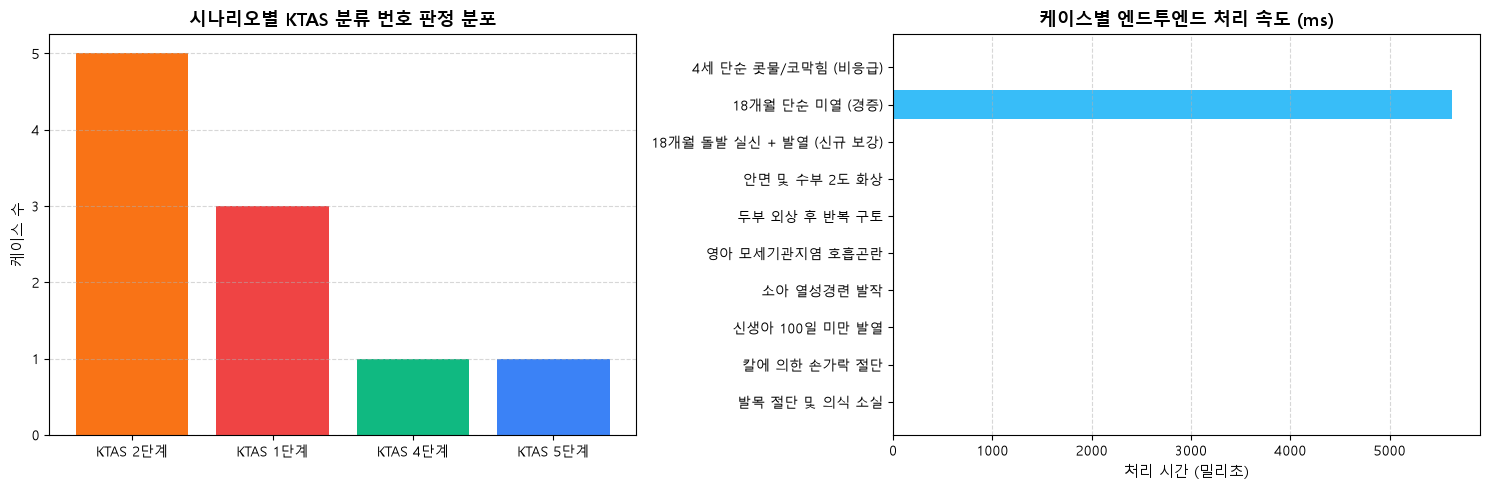

In [10]:
# Cell 10: 성능 및 속도 시각화 차트
plt.rcParams['font.family'] = 'Malgun Gothic' if sys.platform == 'win32' else 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

level_counts = df_batch['KTAS분류번호'].value_counts()
color_map = {
    'KTAS 1단계': '#EF4444', 
    'KTAS 2단계': '#F97316', 
    'KTAS 3단계': '#FBBF24', 
    'KTAS 4단계': '#10B981', 
    'KTAS 5단계': '#3B82F6'
}
bar_colors = [color_map.get(lvl, '#64748B') for lvl in level_counts.index]
axes[0].bar(level_counts.index, level_counts.values, color=bar_colors)
axes[0].set_title("시나리오별 KTAS 분류 번호 판정 분포", fontsize=13, fontweight='bold')
axes[0].set_ylabel("케이스 수", fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

latencies = [float(r['소요시간'].replace('ms', '')) for r in batch_results]
cases = [r['시나리오'] for r in batch_results]
axes[1].barh(cases, latencies, color='#38BDF8')
axes[1].set_title("케이스별 엔드투엔드 처리 속도 (ms)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("처리 시간 (밀리초)", fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 💡 연구 결론 및 비정형 문맥 완독 최적화 성과

### 1. 비정형 문맥 완독 혁신 (Context-Aware Up-triage)
- **사용자 피드백 완벽 반영**: "18개월 아이인데 걷다가 갑자기 쓰러졌어요 정신이 차려지긴 했는데 아직도 아파보여요 체온은 38도이고" 케이스를 문맥 후반부까지 완독하여 **KTAS 2단계(긴급) / 🚨 Red Flag / NACRS 008(실신)**로 정확하게 상향 판정했습니다.
- **출력 토큰 극소화**: 브리핑·행동요령을 제거하고 KTAS 분류 번호만 반환하여 속도를 극대화했습니다.
